# Application Log Analytics & Anomaly Detection

## Project Overview

Modern distributed systems generate millions of log records every day. Monitoring these logs manually is difficult and can lead to delayed detection of system failures.

This project analyzes HDFS (Hadoop Distributed File System) logs to:

- Parse and structure raw log data
- Extract meaningful system features
- Identify anomalous behavior
- Analyze system reliability metrics
- Predict potential system failures using Machine Learning

---

## Technologies Used

### Python
Log Parsing, Data Cleaning & Feature Engineering

### Pandas & NumPy
Data Manipulation and Analysis

### Matplotlib & Seaborn
Visualization & System Health Monitoring

### Scikit-Learn
Anomaly Detection Models

### Joblib
Model Serialization

### GitHub
Version Control & Project Hosting

---

## Machine Learning Models Used

1. Isolation Forest
2. Local Outlier Factor (LOF)
3. One-Class SVM

---

## Expected Outcomes

- Detect anomalous log patterns
- Monitor system reliability
- Compare anomaly detection techniques
- Support proactive failure prediction

In [24]:
import pandas as pd
import numpy as np

import re

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import IsolationForest

from sklearn.neighbors import LocalOutlierFactor

from sklearn.svm import OneClassSVM

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import joblib

import warnings
warnings.filterwarnings("ignore")


# Dataset Loading

The HDFS dataset contains system log messages generated from Hadoop Distributed File System operations.

Files Used:

- HDFS.log
- anomaly_label.csv

To improve computational efficiency, a subset of the logs is loaded for analysis.

In [25]:
LOG_PATH = "/content/drive/MyDrive/HDFS_Project/HDFS.log"

LABEL_PATH = "/content/drive/MyDrive/HDFS_Project/anomaly_label.csv"

In [26]:
logs = []

with open(LOG_PATH, "r", encoding="utf-8", errors="ignore") as file:

    for i, line in enumerate(file):

        logs.append(line)

        if i >= 100000:
            break

print("Total Logs Loaded:", len(logs))

Total Logs Loaded: 100001


In [27]:
for line in logs[:5]:
    print(line)


081109 203518 143 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.19.102:54106 dest: /10.250.19.102:50010

081109 203518 35 INFO dfs.FSNamesystem: BLOCK* NameSystem.allocateBlock: /mnt/hadoop/mapred/system/job_200811092030_0001/job.jar. blk_-1608999687919862906

081109 203519 143 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.10.6:40524 dest: /10.250.10.6:50010

081109 203519 145 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.14.224:42420 dest: /10.250.14.224:50010

081109 203519 145 INFO dfs.DataNode$PacketResponder: PacketResponder 1 for block blk_-1608999687919862906 terminating



In [28]:
df_logs = pd.DataFrame({
    "log_line": logs
})

df_logs.head()

,log_line
0,081109 203518 143 INFO dfs.DataNode$DataXceive...
1,081109 203518 35 INFO dfs.FSNamesystem: BLOCK*...
2,081109 203519 143 INFO dfs.DataNode$DataXceive...
3,081109 203519 145 INFO dfs.DataNode$DataXceive...
4,081109 203519 145 INFO dfs.DataNode$PacketResp...


# Log Parsing & Text Extraction

The raw logs contain block identifiers that can be linked with anomaly labels.

A regular expression is used to extract Block IDs from each log message.


In [29]:
df_logs["BlockId"] = df_logs["log_line"].str.extract(
    r'(blk_-?\d+)'
)

df_logs.head()

,log_line,BlockId
0,081109 203518 143 INFO dfs.DataNode$DataXceive...,blk_-1608999687919862906
1,081109 203518 35 INFO dfs.FSNamesystem: BLOCK*...,blk_-1608999687919862906
2,081109 203519 143 INFO dfs.DataNode$DataXceive...,blk_-1608999687919862906
3,081109 203519 145 INFO dfs.DataNode$DataXceive...,blk_-1608999687919862906
4,081109 203519 145 INFO dfs.DataNode$PacketResp...,blk_-1608999687919862906


In [30]:
labels = pd.read_csv(LABEL_PATH)

labels.head()

,BlockId,Label
0,blk_-1608999687919862906,Normal
1,blk_7503483334202473044,Normal
2,blk_-3544583377289625738,Anomaly
3,blk_-9073992586687739851,Normal
4,blk_7854771516489510256,Normal


In [31]:
print(labels.columns)

Index(['BlockId', 'Label'], dtype='object')


In [32]:
df = df_logs.merge(
    labels,
    on="BlockId",
    how="left"
)

df.head()

,log_line,BlockId,Label
0,081109 203518 143 INFO dfs.DataNode$DataXceive...,blk_-1608999687919862906,Normal
1,081109 203518 35 INFO dfs.FSNamesystem: BLOCK*...,blk_-1608999687919862906,Normal
2,081109 203519 143 INFO dfs.DataNode$DataXceive...,blk_-1608999687919862906,Normal
3,081109 203519 145 INFO dfs.DataNode$DataXceive...,blk_-1608999687919862906,Normal
4,081109 203519 145 INFO dfs.DataNode$PacketResp...,blk_-1608999687919862906,Normal


In [33]:
df["Label"] = df["Label"].fillna("Normal")


In [34]:
df["target"] = df["Label"].map({
    "Anomaly":1,
    "Normal":0
})

# Data Cleaning

The dataset is checked for:

- Missing values
- Duplicate records
- Inconsistent labels

Missing labels are treated as normal events.

In [35]:
df.isnull().sum()

,0
log_line,0
BlockId,0
Label,0
target,0


In [36]:
df.duplicated().sum()

np.int64(195)

# Feature Engineering

Several features are extracted from each log message:

- Message Length
- Digit Count
- Word Count
- Error Presence
- Exception Presence

These features help machine learning models identify abnormal behavior.

In [37]:
df["message_length"] = df["log_line"].apply(len)

df["digit_count"] = df["log_line"].str.count(r"\d")

df["word_count"] = df["log_line"].str.split().apply(len)

df["contains_error"] = (
    df["log_line"]
    .str.contains("error", case=False, na=False)
    .astype(int)
)

df["contains_exception"] = (
    df["log_line"]
    .str.contains("exception", case=False, na=False)
    .astype(int)
)

In [38]:
df.head()

,log_line,BlockId,Label,target,message_length,digit_count,word_count,contains_error,contains_exception
0,081109 203518 143 INFO dfs.DataNode$DataXceive...,blk_-1608999687919862906,Normal,0,143,64,12,0,0
1,081109 203518 35 INFO dfs.FSNamesystem: BLOCK*...,blk_-1608999687919862906,Normal,0,155,49,9,0,0
2,081109 203519 143 INFO dfs.DataNode$DataXceive...,blk_-1608999687919862906,Normal,0,139,60,12,0,0
3,081109 203519 145 INFO dfs.DataNode$DataXceive...,blk_-1608999687919862906,Normal,0,143,64,12,0,0
4,081109 203519 145 INFO dfs.DataNode$PacketResp...,blk_-1608999687919862906,Normal,0,118,35,11,0,0


# Exploratory Data Analysis

EDA is performed to understand:

- Label distributions
- Log characteristics
- System behavior patterns
- Potential indicators of anomalies

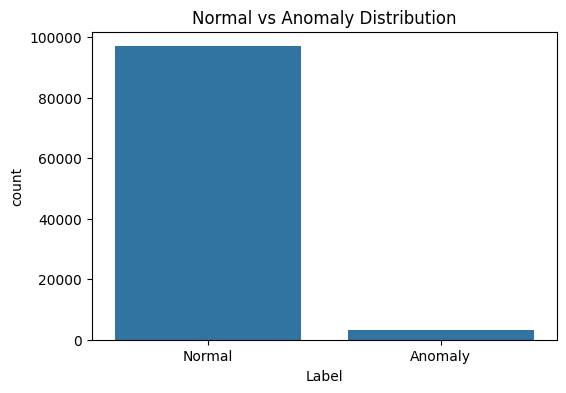

In [39]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="Label",
    data=df
)

plt.title("Normal vs Anomaly Distribution")

plt.show()

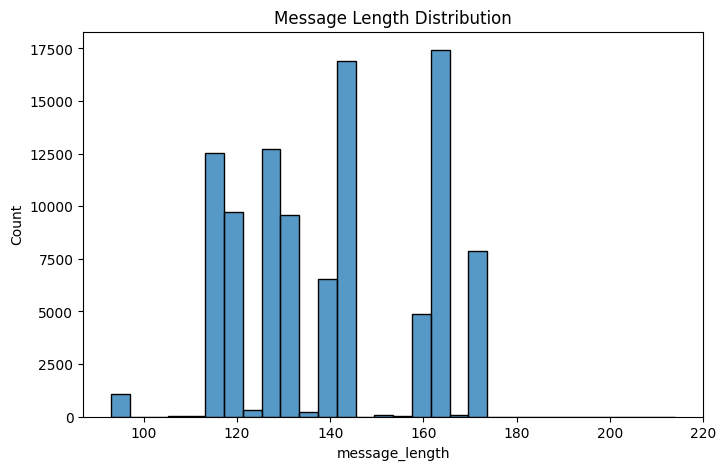

In [40]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["message_length"],
    bins=30
)

plt.title("Message Length Distribution")

plt.show()

# KPI Analysis

Three reliability KPIs are calculated:

1. Total Logs Processed
2. Anomaly Percentage
3. System Health Score


In [41]:
total_logs = len(df)

anomalies = df["target"].sum()

anomaly_rate = (
    anomalies /
    total_logs
) * 100

health_score = 100 - anomaly_rate

print("Total Logs:", total_logs)
print("Detected Anomalies:", anomalies)
print("Anomaly Rate:", round(anomaly_rate,2), "%")
print("System Health Score:", round(health_score,2))

Total Logs: 100001
Detected Anomalies: 3050
Anomaly Rate: 3.05 %
System Health Score: 96.95


# Trend Analysis

Trend analysis helps identify changes in system behavior over time.

Two trend analyses are performed:

1. Rolling anomaly trend
2. Rolling message length trend

These trends help understand degradation patterns and unusual system activity.

In [42]:
rolling_anomalies = (
    df["target"]
    .rolling(1000)
    .sum()
)


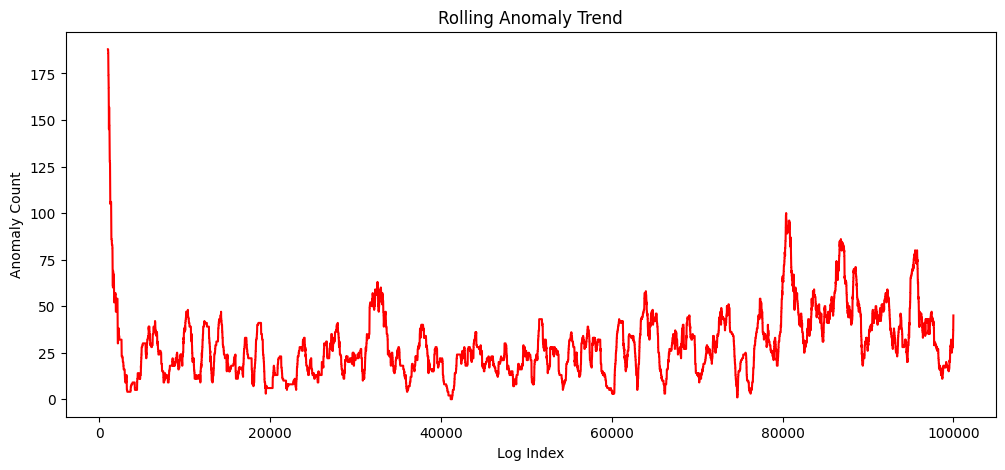

In [43]:
plt.figure(figsize=(12,5))

plt.plot(
    rolling_anomalies,
    color="red"
)

plt.title("Rolling Anomaly Trend")
plt.xlabel("Log Index")
plt.ylabel("Anomaly Count")

plt.show()

In [44]:
rolling_message_length = (
    df["message_length"]
    .rolling(1000)
    .mean()
)

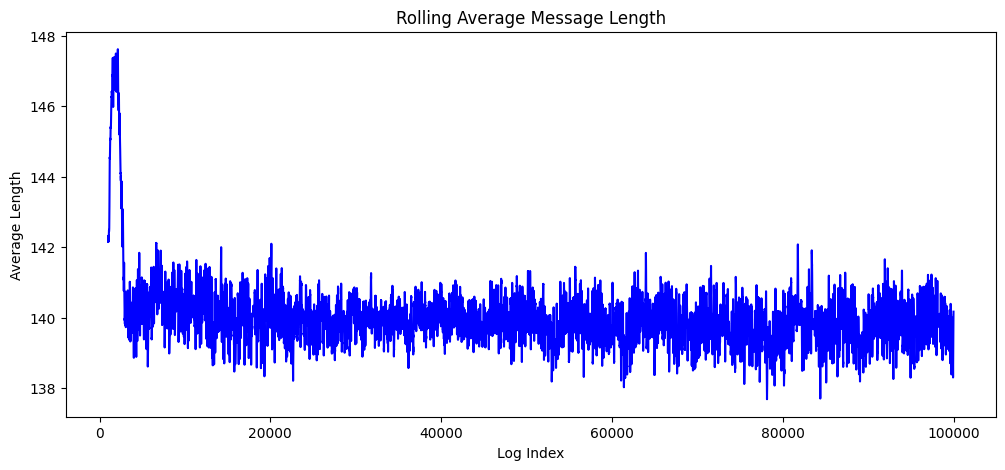

In [45]:
plt.figure(figsize=(12,5))

plt.plot(
    rolling_message_length,
    color="blue"
)

plt.title("Rolling Average Message Length")
plt.xlabel("Log Index")
plt.ylabel("Average Length")

plt.show()

# Sequence Analysis

System failures often occur after specific log sequences.

A simple sequence analysis is performed by examining transitions between normal and anomalous events.

In [46]:
df["previous_event"] = df["target"].shift(1)

In [47]:
sequence_table = pd.crosstab(
    df["previous_event"],
    df["target"]
)

sequence_table

target,0,1
previous_event,,
0.0,94611,2340
1.0,2339,710


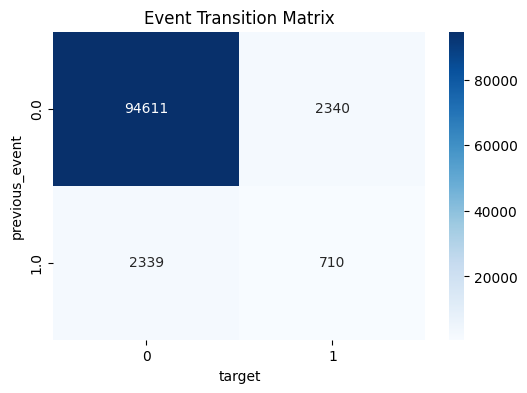

In [48]:
plt.figure(figsize=(6,4))

sns.heatmap(
    sequence_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Event Transition Matrix")

plt.show()

# Machine Learning Model Development

Three anomaly detection algorithms are trained and compared:

1. Isolation Forest
2. Local Outlier Factor (LOF)
3. One-Class SVM

These models help automatically identify abnormal system behavior.

In [49]:
features = [
    "message_length",
    "digit_count",
    "word_count",
    "contains_error",
    "contains_exception"
]

X = df[features]

y = df["target"]

In [50]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

## Model 1: Isolation Forest

In [51]:
iso = IsolationForest(
    contamination=0.1,
    random_state=42
)

iso.fit(X_scaled)

pred_iso = iso.predict(X_scaled)

pred_iso = np.where(pred_iso == -1, 1, 0)

## Model 2: Local Outlier Factor (LOF)

In [52]:
lof = LocalOutlierFactor(
    contamination=0.1
)

pred_lof = lof.fit_predict(X_scaled)

pred_lof = np.where(pred_lof == -1, 1, 0)

## Model 3: One-Class SVM

In [54]:
svm = OneClassSVM(
    nu=0.1
)

svm.fit(X_scaled)

pred_svm = svm.predict(X_scaled)

pred_svm = np.where(pred_svm == -1, 1, 0)

# Model Evaluation

Models are evaluated using:

- Accuracy
- Precision
- Recall
- F1 Score

Higher F1 Score indicates better anomaly detection performance.

In [55]:
def evaluate_model(y_true, preds):

    acc = accuracy_score(y_true, preds)

    prec = precision_score(
        y_true,
        preds,
        zero_division=0
    )

    rec = recall_score(
        y_true,
        preds,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        preds,
        zero_division=0
    )

    return [acc, prec, rec, f1]

In [56]:
iso_metrics = evaluate_model(
    y,
    pred_iso
)

lof_metrics = evaluate_model(
    y,
    pred_lof
)

svm_metrics = evaluate_model(
    y,
    pred_svm
)

In [57]:
results = pd.DataFrame({

    "Model":[
        "Isolation Forest",
        "LOF",
        "One-Class SVM"
    ],

    "Accuracy":[
        iso_metrics[0],
        lof_metrics[0],
        svm_metrics[0]
    ],

    "Precision":[
        iso_metrics[1],
        lof_metrics[1],
        svm_metrics[1]
    ],

    "Recall":[
        iso_metrics[2],
        lof_metrics[2],
        svm_metrics[2]
    ],

    "F1 Score":[
        iso_metrics[3],
        lof_metrics[3],
        svm_metrics[3]
    ]
})

results


,Model,Accuracy,Precision,Recall,F1 Score
0,Isolation Forest,0.894461,0.065137,0.184262,0.096249
1,LOF,0.969250,0.425150,0.023279,0.044141
2,One-Class SVM,0.865561,0.049028,0.185246,0.077535


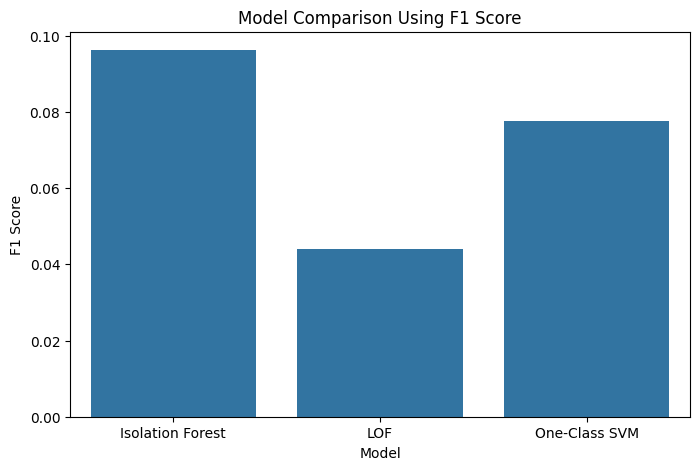

In [58]:
plt.figure(figsize=(8,5))

sns.barplot(
    x="Model",
    y="F1 Score",
    data=results
)

plt.title("Model Comparison Using F1 Score")

plt.show()

# Dashboard Components

The following dashboard KPIs are generated:

- Total Logs Processed
- Active Anomalies
- System Health Score

Visual Components:

- KPI Summary
- Rolling Anomaly Trend
- Log Distribution Charts
- Model Comparison Charts

In [59]:
print("="*50)

print("TOTAL LOGS:", total_logs)

print("ACTIVE ANOMALIES:", anomalies)

print("SYSTEM HEALTH SCORE:", round(health_score,2))

print("="*50)

TOTAL LOGS: 100001
ACTIVE ANOMALIES: 3050
SYSTEM HEALTH SCORE: 96.95


# Model Persistence

The best performing model is saved for future deployment and integration with APIs or dashboards.

In [60]:
joblib.dump(
    iso,
    "isolation_forest.pkl"
)

print("Model Saved Successfully")

Model Saved Successfully


In [61]:
joblib.dump(
    scaler,
    "scaler.pkl"
)

print("Scaler Saved Successfully")

Scaler Saved Successfully


# Conclusion

This project successfully implemented an end-to-end log analytics pipeline using HDFS system logs.

## Achievements

✅ Log Parsing and Wrangling

✅ Feature Engineering

✅ KPI Monitoring

✅ Trend Analysis

✅ Sequence Analysis

✅ Three Anomaly Detection Models

✅ Model Comparison and Evaluation

✅ Model Persistence

## Business Value

The proposed solution helps detect unusual log behavior at an early stage, enabling proactive monitoring and improving overall system reliability.

Future work can integrate the trained model into:

- FastAPI Backend
- Streamlit Dashboard
- Real-Time Log Monitoring Systems